# 1D flux power spectrum on the uniform grid: with HCDs, without DLAs, without HCDs

Reads the output of `instructions/03_run_grid_pipeline.py` (3 x N_SIDE² sightlines
across the whole box, `SIM_NAME` and `N_SIDE` in CELL 2) and compares the P1D of the
three cases:

- `total`: all the gas (LyA with HCDs).
- `noDLA`: absorbers with log N_HI ≥ 20.3 removed (LyA without DLAs).
- `noHCD`: absorbers with log N_HI ≥ 17.2 removed (LyA without HCDs).

Absorbers are removed as gas cells (peak + blend decomposition of the fork, no halo
window), not as masked pixels. P1D as in `fake_spectra.fluxstatistics.flux_power`:
δF = F / F̄ − 1, each case with its own mean flux, no mean-flux rescaling.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ==============================================================================
# CELL 1: CONFIGURATION & STYLE
# ==============================================================================
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
%load_ext autoreload
%autoreload 2
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# One style per case. Okabe-Ito colours, as in the other notebooks
# (Forest = E69F00, as in CLASS_COLORS); the line style tells them apart too.
CASE_STYLES = {
    'total': {'color': 'black',   'ls': '-',  'label': r'Ly$\alpha$ with HCDs (total)'},
    'noDLA': {'color': '#0072B2', 'ls': '--', 'label': r'Ly$\alpha$ without DLAs ($\log N_{\rm HI} \geq 20.3$ removed)'},
    'noHCD': {'color': '#E69F00', 'ls': '-.', 'label': r'Ly$\alpha$ without HCDs ($\log N_{\rm HI} \geq 17.2$ removed)'},
}


In [2]:
# ==============================================================================
# CELL 2: SIMULATION, PATHS AND LOADING
# ==============================================================================
from pathlib import Path

# Must match the CONFIG of instructions/03_run_grid_pipeline.py
SIM_NAME = "TNG50-2"
N_SIDE   = 256

# Project root = the folder that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())

# Default output folder of the grid driver (OUTPUT_DIRNAME = None)
DATA_DIR  = PROJ_ROOT / f"data_{SIM_NAME}_snap025_grid{N_SIDE}_peak_plus_blend_sfneutral_1e4K_H2"
DATA_FILE = DATA_DIR / f"{SIM_NAME}_z3_Grid{N_SIDE}x{N_SIDE}x3_total_noHCD_noDLA.pkl"
PLOTS_DIR = PROJ_ROOT / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

df   = pd.read_pickle(DATA_FILE)
meta = dict(df.attrs)          # shared grids and constants
CASES = list(meta['cases'])    # case names = column suffixes

print("file      :", DATA_FILE.name)
print("sightlines:", f"{len(df):,} / {meta['n_expected']:,}")
for name, c in meta['cases'].items():
    print(f"case {name:6s}: {c['filter_mode']}, log N_HI threshold = {c['log_nhi_thresh']}")
print(f"z = {meta['redshift']:.3f}, nbins = {meta['nbins']}, "
      f"dv = {meta['dvbin']:.2f} km/s, vmax = {meta['vmax']:.1f} km/s")


file      : TNG50-2_z3_Grid256x256x3_total_noHCD_noDLA.pkl
sightlines: 196,608 / 196,608
case total : None, log N_HI threshold = None
case noHCD : Forest_only, log N_HI threshold = 17.2
case noDLA : Forest_only, log N_HI threshold = 20.3
z = 3.008, nbins = 396, dv = 10.00 km/s, vmax = 3961.5 km/s


In [3]:
# ==============================================================================
# CELL 3: FLUX ARRAYS AND HOW MANY SIGHTLINES EACH CASE CHANGES
# ==============================================================================
# (n_sightlines, nbins) flux per case, float32 to keep memory low
flux = {c: np.stack(df[f'flux_{c}'].to_numpy()) for c in CASES}

for c in CASES:
    line = f"{c:6s}  <F> = {flux[c].mean():.4f}"
    if c != 'total':
        # Sightlines that lost some gas, and those that lost all of it (a strong
        # DLA blacks out the whole box, so the blend test removes everything)
        changed = df[f'log_n_hi_{c}'] < df['log_n_hi_total'] - 1e-6
        emptied = df[f'log_n_hi_{c}'] == 0.0
        line += f"   changed: {changed.mean():.3%}   emptied: {emptied.mean():.3%}"
    print(line)


total   <F> = 0.5401
noHCD   <F> = 0.5614   changed: 13.857%   emptied: 0.026%
noDLA   <F> = 0.5450   changed: 0.842%   emptied: 0.026%


In [4]:
# ==============================================================================
# CELL 4: P1D OF EACH CASE
# ==============================================================================
import fake_spectra.fluxstatistics as fstat

def p1d(flux_2d, vmax):
    """P1D [km/s] and k [s/km] with fake_spectra's own flux_power.

    flux_power wants tau: tau = -ln F. Saturated pixels (F = 0 in float32) are
    clipped to tau = 69, i.e. F = 1e-30, which is 0 for the power spectrum.
    No mean-flux rescaling: each case uses its own mean flux.
    """
    tau = -np.log(np.clip(flux_2d.astype(np.float64), 1e-30, None))
    kf, pk = fstat.flux_power(tau, vmax, spec_res=0, mean_flux_desired=None, window=False)
    return kf[1:], pk[1:]          # drop k = 0, as Spectra.get_flux_power_1D

P1D = {}
for c in CASES:
    P1D[c] = p1d(flux[c], meta['vmax'])
    print(f"{c:6s}  {len(P1D[c][0])} k-modes, "
          f"k = {P1D[c][0][0]:.4f} ... {P1D[c][0][-1]:.3f} s/km")


total   198 k-modes, k = 0.0016 ... 0.314 s/km
noHCD   198 k-modes, k = 0.0016 ... 0.314 s/km
noDLA   198 k-modes, k = 0.0016 ... 0.314 s/km


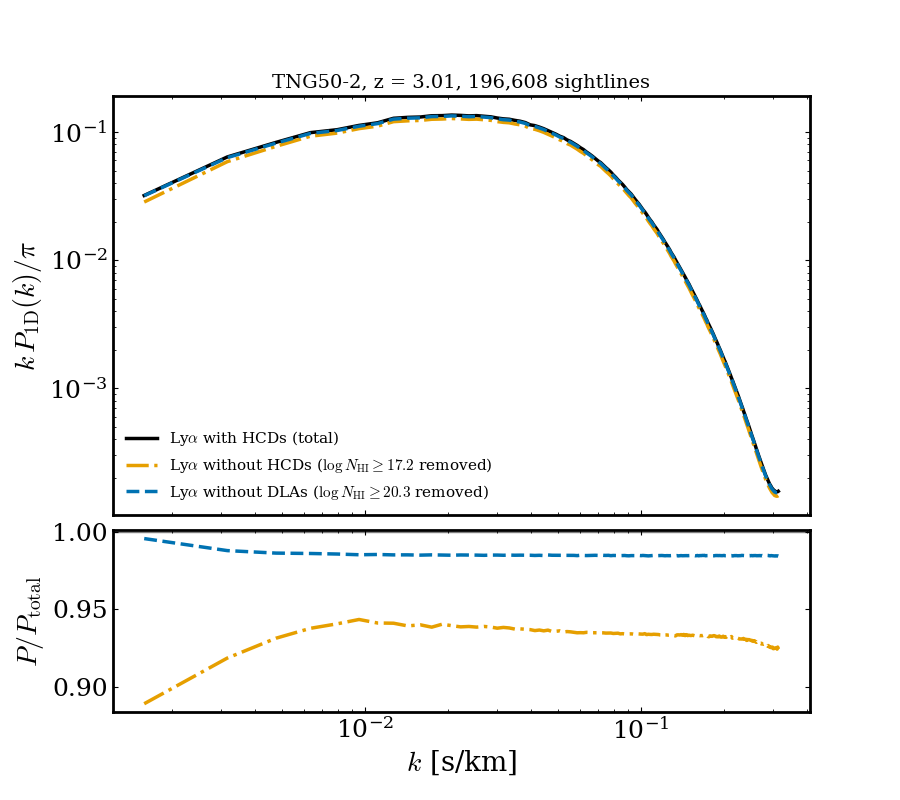

In [5]:
# ==============================================================================
# CELL 5: P1D COMPARISON (top: k P/pi, bottom: ratio to the total)
# ==============================================================================
fig, (ax, ax_r) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1.3], 'hspace': 0.05})

k, pk_tot = P1D['total']
for c in CASES:
    k, pk = P1D[c]
    st = CASE_STYLES.get(c, {'color': 'gray', 'ls': ':', 'label': c})
    ax.plot(k, k * pk / np.pi, color=st['color'], ls=st['ls'], label=st['label'])
    # Effect of removing the absorbers: case over total (1 = no effect)
    if c != 'total':
        ax_r.plot(k, pk / pk_tot, color=st['color'], ls=st['ls'])

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r'$k\,P_{\rm 1D}(k)/\pi$')
ax.legend(frameon=False, loc='lower left', fontsize=11)
ax.set_title(f"{SIM_NAME}, z = {meta['redshift']:.2f}, "
             f"{len(df):,} sightlines", fontsize=14)

ax_r.axhline(1.0, color='gray', lw=1, zorder=0)
ax_r.set_xlabel(r'$k$ [s/km]')
ax_r.set_ylabel(r'$P / P_{\rm total}$')

fig.savefig(PLOTS_DIR / f"P1D_grid_{SIM_NAME}_{N_SIDE}.pdf", bbox_inches='tight')
plt.show()


In [6]:
# ==============================================================================
# CELL 6: MEAN BIAS OF THE P1D WITHOUT DLAs AND WITHOUT HCDs
# ==============================================================================
# The power scales as the bias squared, so the ratio to the total is
# b²(k) = P_case / P_total   (b² = 1: no effect, b² < 1: less power).
# The HCD effect lives on large scales, so the mean is also given for k <= K_MAX.
K_MAX = 0.02    # s/km, large-scale limit

k, pk_tot = P1D['total']
large = k <= K_MAX

for c in ['noDLA', 'noHCD']:
    b2_k = P1D[c][1] / pk_tot
    print(f"{c:6s}  <b²> (all k) = {b2_k.mean():.4f}   "
          f"<b²> (k <= {K_MAX} s/km, {large.sum()} modes) = {b2_k[large].mean():.4f}   "
          f"b = sqrt(<b²>) = {np.sqrt(b2_k[large].mean()):.4f}")


noDLA   <b²> (all k) = 0.9849   <b²> (k <= 0.02 s/km, 12 modes) = 0.9865   b = sqrt(<b²>) = 0.9932
noHCD   <b²> (all k) = 0.9324   <b²> (k <= 0.02 s/km, 12 modes) = 0.9335   b = sqrt(<b²>) = 0.9662


## Why the P1D drops: one sightline with a DLA

Top: flux of the same sightline with and without the DLA. Bottom: δF = F / F̄ − 1,
each case with its own mean flux (as in `flux_power`). Removing the DLA erases a wide
trough (large-scale power) and raises F̄, which shrinks δF everywhere.

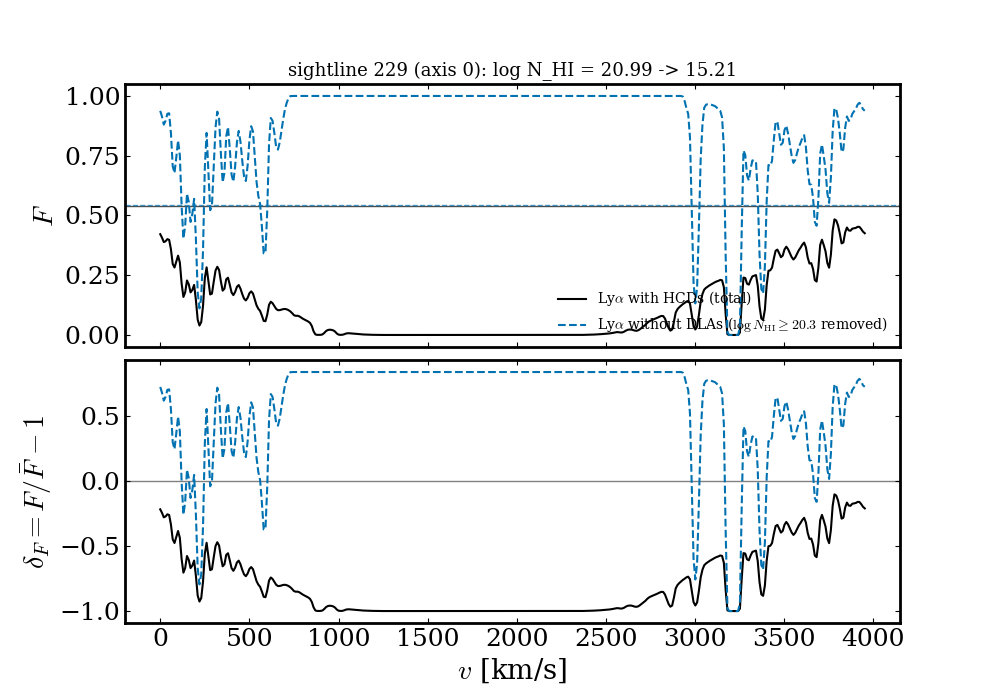

1,604 sightlines with a DLA removed (showing #0)


In [7]:
# ==============================================================================
# CELL 7: ONE SIGHTLINE WITH A DLA, total vs noDLA
# ==============================================================================
# Sightlines where the DLA removal changed the gas but did not empty the box
has_dla = (df['log_n_hi_noDLA'] < df['log_n_hi_total'] - 1e-6) & (df['log_n_hi_noDLA'] > 0.0)
idx_dla = np.flatnonzero(has_dla.to_numpy())
I_PICK  = 0                      # change to look at another DLA sightline
row     = idx_dla[I_PICK]

v = meta['v_grid']               # velocity along the sightline [km/s]
fig, (ax, ax_d) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={'hspace': 0.05})

for c in ['total', 'noDLA']:
    st = CASE_STYLES[c]
    F  = flux[c][row]
    # δF with the mean flux of the whole case (not of this sightline), as in the P1D
    dF = F / flux[c].mean() - 1.0
    ax.plot(v, F, color=st['color'], ls=st['ls'], lw=1.5, label=st['label'])
    # Mean flux of the whole case (δF = 0 in the panel below)
    ax.axhline(flux[c].mean(), color=st['color'], ls=st['ls'], lw=1, alpha=0.7)
    ax_d.plot(v, dF, color=st['color'], ls=st['ls'], lw=1.5)

ax.set_ylabel(r'$F$')
ax.set_ylim(-0.05, 1.05)
ax.legend(frameon=False, loc='lower right', fontsize=10)
ax.set_title(f"sightline {df['skewer_id'].iloc[row]} (axis {df['axis'].iloc[row]}): "
             f"log N_HI = {df['log_n_hi_total'].iloc[row]:.2f} -> "
             f"{df['log_n_hi_noDLA'].iloc[row]:.2f}", fontsize=13)

ax_d.axhline(0.0, color='gray', lw=1, zorder=0)
ax_d.set_ylabel(r'$\delta_F = F/\bar F - 1$')
ax_d.set_xlabel(r'$v$ [km/s]')
plt.show()

print(f"{len(idx_dla):,} sightlines with a DLA removed (showing #{I_PICK})")


## Separating the mean-flux effect from the absorber shape

Removing absorbers raises F̄, and δF = F / F̄ − 1 then shrinks at all k. To isolate the
effect of the absorbers' shape, every case is normalised by the **same** F̄ (that of
`total`). Since F / F̄_total − 1 = r (δF_case + 1) − 1 with r = F̄_case / F̄_total, for
k > 0 this is exactly P_case × r². (`flux_power(mean_flux_desired=...)` is not used
because it rescales τ, i.e. it changes the forest itself.)

noHCD   F̄ = 0.5614   <P/P_total> (k <= 0.02) = 1.0088   (all k) = 1.0076
noDLA   F̄ = 0.5450   <P/P_total> (k <= 0.02) = 1.0048   (all k) = 1.0031


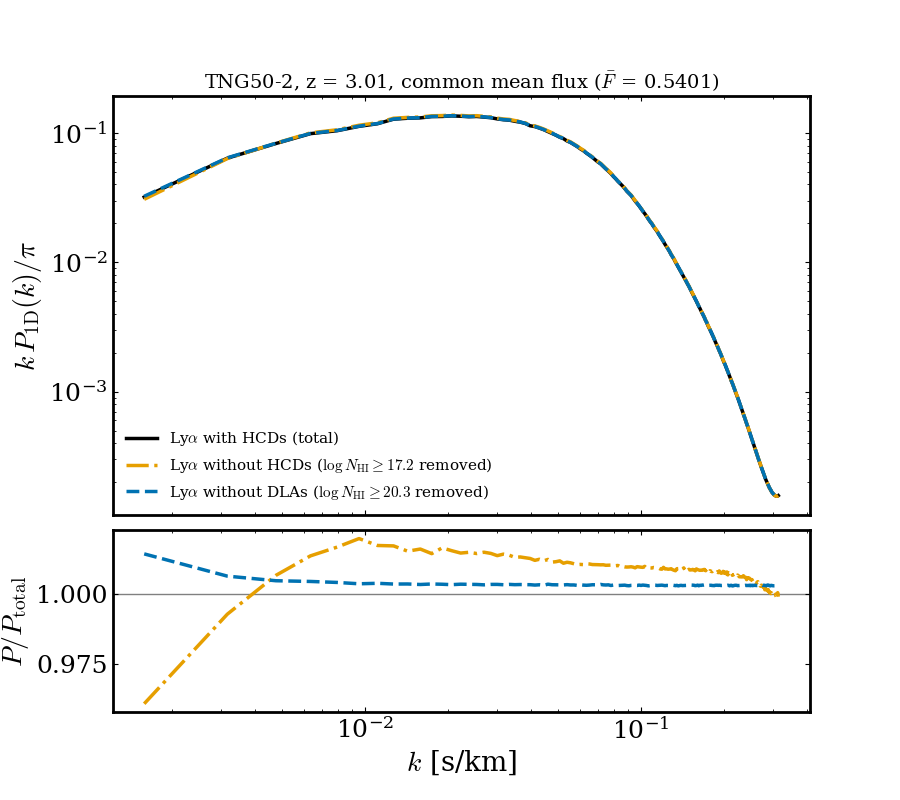

In [8]:
# ==============================================================================
# CELL 8: P1D WITH A COMMON MEAN FLUX (top: k P/pi, bottom: ratio to the total)
# ==============================================================================
# Mean flux of each case, in float64 for precision
Fbar = {c: flux[c].mean(dtype=np.float64) for c in CASES}

# Same normalisation for all cases: P_common = P_case * (F̄_case / F̄_total)²
P1D_common = {c: (P1D[c][0], P1D[c][1] * (Fbar[c] / Fbar['total'])**2) for c in CASES}

fig, (ax, ax_r) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1.3], 'hspace': 0.05})

k, pk_tot = P1D_common['total']
for c in CASES:
    k, pk = P1D_common[c]
    st = CASE_STYLES.get(c, {'color': 'gray', 'ls': ':', 'label': c})
    ax.plot(k, k * pk / np.pi, color=st['color'], ls=st['ls'], label=st['label'])
    # Shape effect of removing the absorbers (1 = no effect)
    if c != 'total':
        ax_r.plot(k, pk / pk_tot, color=st['color'], ls=st['ls'])
        print(f"{c:6s}  F̄ = {Fbar[c]:.4f}   <P/P_total> (k <= {K_MAX}) = "
              f"{(pk / pk_tot)[large].mean():.4f}   (all k) = {(pk / pk_tot).mean():.4f}")

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r'$k\,P_{\rm 1D}(k)/\pi$')
ax.legend(frameon=False, loc='lower left', fontsize=11)
ax.set_title(f"{SIM_NAME}, z = {meta['redshift']:.2f}, common mean flux "
             f"($\\bar F$ = {Fbar['total']:.4f})", fontsize=14)

ax_r.axhline(1.0, color='gray', lw=1, zorder=0)
ax_r.set_xlabel(r'$k$ [s/km]')
ax_r.set_ylabel(r'$P / P_{\rm total}$')

fig.savefig(PLOTS_DIR / f"P1D_grid_{SIM_NAME}_{N_SIDE}_commonF.pdf", bbox_inches='tight')
plt.show()